# Artist Diary Exploratory Data Analysis

## Overview

The Artist Diary Analytics Mart provides an artist-level view of movie participation and performance.

The dataset combines artist, casting, movie, genre, language, production, popularity, and financial information into an analytical dataset.

The objective of this exploratory data analysis is to understand:

- Artist participation in movies.
- Artist career activity.
- Movie and character participation.
- Genre preferences and exposure.
- Language exposure.
- Production company and country exposure.
- Movie popularity associated with artists.
- Financial performance of movies associated with artists.
- Relationships between artist participation and movie performance.
- Potential patterns and business insights.

## Analytical Grain

The Artist Diary is defined at:

**1 row = 1 Artist × Movie × Character**

This grain must be maintained throughout the analysis.

## Key Analytical Questions

1. Which artists have appeared in the most movies?
2. Which artists have the widest genre exposure?
3. Which artists have worked across the most production countries?
4. Which artists have the highest average movie popularity?
5. Which artists are associated with the highest-grossing movies?
6. Which genres have the largest number of artist appearances?
7. How does artist participation vary across time?
8. Are highly active artists associated with higher-performing movies?
9. Which production companies have worked with the most artists?
10. What patterns can be identified from the artist career data?

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
artist_diary = pd.read_csv(r"C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\artist_diary.csv")

In [6]:
artist_diary.head()

,Artist_ID,Artist_Name,Gender,Character_Name,Movie_ID,Movie_Title,Release_Date,Popularity,Budget,Revenue,Genres,Languages,Production_Companies,Production_Countries
0,1496,Tod Browning,2,Crook (uncredited),3059,Intolerance,1916-09-04 00:00:00.000000,3.232447,385907,8394751.0,Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
1,3247,Noble Johnson,2,Babylonian Soldier (uncredited),3059,Intolerance,1916-09-04 00:00:00.000000,3.232447,385907,8394751.0,Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
2,8630,Erich von Stroheim,0,Second Pharisee (uncredited),3059,Intolerance,1916-09-04 00:00:00.000000,3.232447,385907,8394751.0,Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
3,8728,Eugene Pallette,2,Prosper Latour (French Story),3059,Intolerance,1916-09-04 00:00:00.000000,3.232447,385907,8394751.0,Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
4,8820,Joseph Henabery,2,L'amiral de Coligny / Defendant,3059,Intolerance,1916-09-04 00:00:00.000000,3.232447,385907,8394751.0,Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America


In [7]:
artist_diary.shape

(106257, 14)

In [8]:
artist_diary.info()

<class 'pandas.DataFrame'>
RangeIndex: 106257 entries, 0 to 106256
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Artist_ID             106257 non-null  int64  
 1   Artist_Name           106257 non-null  str    
 2   Gender                106257 non-null  int64  
 3   Character_Name        105574 non-null  str    
 4   Movie_ID              106257 non-null  int64  
 5   Movie_Title           106257 non-null  str    
 6   Release_Date          106257 non-null  str    
 7   Popularity            106257 non-null  float64
 8   Budget                106257 non-null  int64  
 9   Revenue               106257 non-null  float64
 10  Genres                106179 non-null  str    
 11  Languages             105710 non-null  str    
 12  Production_Companies  103104 non-null  str    
 13  Production_Countries  104894 non-null  str    
dtypes: float64(2), int64(4), str(8)
memory usage: 11.3 MB


In [9]:
artist_diary.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Artist_ID,106257.0,NaN,NaN,NaN,453207.109565,627461.546867,1.0,16511.0,74036.0,1093974.0,1893207.0
Artist_Name,106257,54201,Samuel L. Jackson,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,106257.0,NaN,NaN,NaN,1.136386,0.868313,0.0,0.0,1.0,2.0,2.0
Character_Name,105574,71576,Himself,909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Movie_ID,106257.0,NaN,NaN,NaN,56237.55713,87536.968191,5.0,5915.0,12797.0,61752.0,459488.0
Movie_Title,106257,4757,Rock of Ages,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Release_Date,106257,3263,2014-12-25 00:00:00.000000,321,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Popularity,106257.0,NaN,NaN,NaN,31.615308,40.690681,0.000372,8.864368,20.601483,41.273567,875.581305
Budget,106257.0,NaN,NaN,NaN,41275182.617428,50749205.803068,0.0,6000000.0,25000000.0,55000000.0,380000000.0
Revenue,106257.0,NaN,NaN,NaN,137161231.114919,233344788.231048,0.0,5321508.0,50068310.0,161001698.0,2787965087.0


In [10]:
artist_diary.duplicated().sum()

np.int64(0)

In [11]:
artist_diary.duplicated(
    subset=[
        "Artist_ID",
        "Movie_ID",
        "Character_Name"
    ]
).sum()

np.int64(0)

In [12]:
artist_diary.isna().sum().sort_values(
    ascending=False
)

Production_Companies    3153
Production_Countries    1363
Character_Name           683
Languages                547
Genres                    78
Artist_ID                  0
Artist_Name                0
Gender                     0
Movie_ID                   0
Movie_Title                0
Release_Date               0
Popularity                 0
Budget                     0
Revenue                    0
dtype: int64

In [13]:
artist_diary["Artist_ID"].nunique()

54588

In [14]:
#Most Active Artists
artist_movie_count = (
    artist_diary
    .groupby(
        ["Artist_ID", "Artist_Name"]
    )
    ["Movie_ID"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

artist_movie_count.head(20)


Artist_ID  Artist_Name      
2231       Samuel L. Jackson    67
380        Robert De Niro       57
62         Bruce Willis         51
1892       Matt Damon           48
192        Morgan Freeman       46
884        Steve Buscemi        43
3896       Liam Neeson          41
85         Johnny Depp          40
887        Owen Wilson          40
1230       John Goodman         39
7447       Alec Baldwin         39
2963       Nicolas Cage         39
2283       Stanley Tucci        38
5293       Willem Dafoe         38
388        Jim Broadbent        38
287        Brad Pitt            38
13242      Paul Giamatti        37
23659      Will Ferrell         37
4038       Susan Sarandon       36
28633      Richard Jenkins      36
Name: Movie_ID, dtype: int64

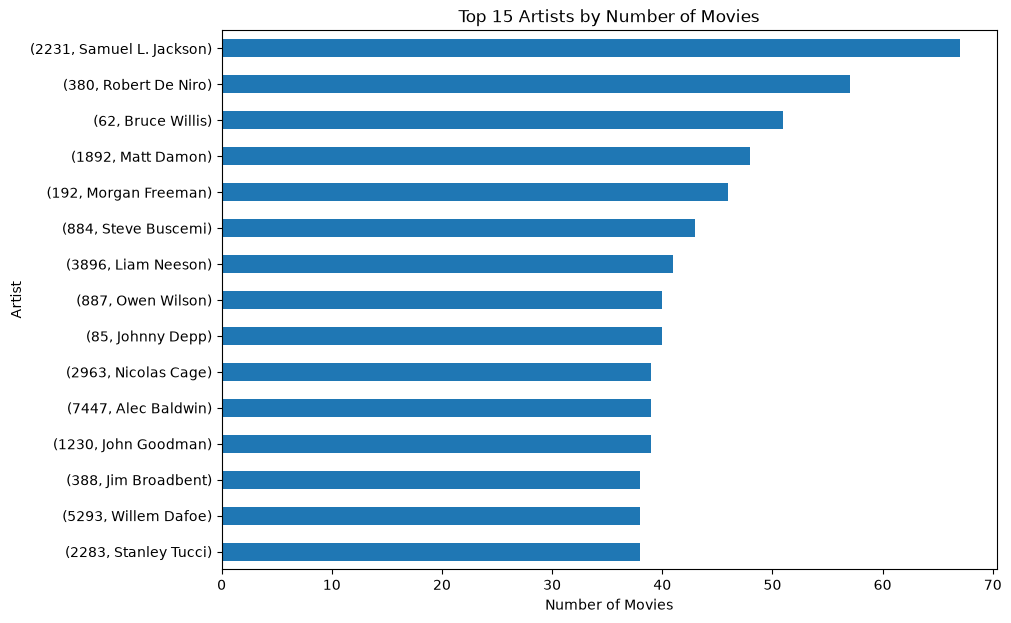

In [15]:
#Visualization
top_artists = artist_movie_count.head(15)

top_artists.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top 15 Artists by Number of Movies")
plt.xlabel("Number of Movies")
plt.ylabel("Artist")
plt.show()

In [16]:
#Artist Career Distribution
artist_activity = (
    artist_diary
    .groupby("Artist_ID")
    ["Movie_ID"]
    .nunique()
)

artist_activity.describe()

count    54588.000000
mean         1.943358
std          2.826097
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         67.000000
Name: Movie_ID, dtype: float64

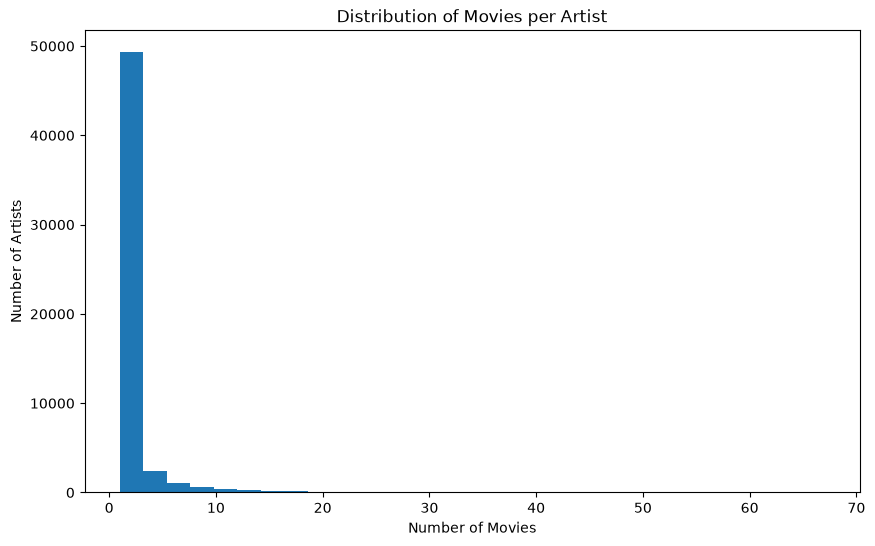

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(
    artist_activity,
    bins=30
)

plt.title("Distribution of Movies per Artist")
plt.xlabel("Number of Movies")
plt.ylabel("Number of Artists")

plt.show()

In [18]:
#Gender Analysis
gender_distribution = (
    artist_diary
    .groupby("Gender")
    ["Artist_ID"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

gender_distribution

Gender
0    27725
2    16406
1    10457
Name: Artist_ID, dtype: int64

In [19]:
gender_movie_participation = (
    artist_diary
    .groupby("Gender")
    ["Movie_ID"]
    .nunique()
)

gender_movie_participation

Gender
0    4156
1    4496
2    4691
Name: Movie_ID, dtype: int64

In [20]:
gender_popularity = (
    artist_diary
    .groupby("Gender")
    ["Popularity"]
    .mean()
    .sort_values(
        ascending=False
    )
)

gender_popularity

Gender
0    34.493193
2    31.203231
1    28.413833
Name: Popularity, dtype: float64

In [21]:
# Character Analysis
artist_character_count = (
    artist_diary
    .groupby(
        ["Artist_ID", "Artist_Name"]
    )
    ["Character_Name"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

artist_character_count.head(20)

Artist_ID  Artist_Name       
2231       Samuel L. Jackson     59
380        Robert De Niro        54
62         Bruce Willis          45
1892       Matt Damon            43
192        Morgan Freeman        41
884        Steve Buscemi         40
2963       Nicolas Cage          39
1230       John Goodman          39
7447       Alec Baldwin          39
13242      Paul Giamatti         37
388        Jim Broadbent         37
287        Brad Pitt             37
3896       Liam Neeson           37
85         Johnny Depp           36
4038       Susan Sarandon        36
28633      Richard Jenkins       36
2283       Stanley Tucci         36
4690       Christopher Walken    35
5293       Willem Dafoe          35
2282       Ben Kingsley          34
Name: Character_Name, dtype: int64

In [22]:
(
    artist_diary["Character_Name"]
    .value_counts()
    .head(20)
)

Character_Name
Himself                      909
Dancer                       375
Additional Voices (voice)    323
Herself                      229
Reporter                     136
Doctor                       132
Nurse                        117
Waitress                     108
Bartender                     93
Extra: Bar / Comedy Club      85
Paul                          81
Cop                           81
Student                       80
Sam                           78
Security Guard                78
(voice)                       77
Jack                          72
Frank                         70
Choir                         69
Priest                        68
Name: count, dtype: int64

In [23]:
# Movie Participation Analysis
artists_per_movie = (
    artist_diary
    .groupby("Movie_ID")
    ["Artist_ID"]
    .nunique()
)

artists_per_movie.describe()

count    4760.000000
mean       22.286555
std        19.514108
min         1.000000
25%        11.000000
50%        17.000000
75%        25.000000
max       224.000000
Name: Artist_ID, dtype: float64

In [24]:
(
    artist_diary
    .groupby(
        ["Movie_ID", "Movie_Title"]
    )
    ["Artist_ID"]
    .nunique()
    .sort_values(
        ascending=False
    )
    .head(20)
)

Movie_ID  Movie_Title                       
80585     Rock of Ages                          224
3083      Mr. Smith Goes to Washington          213
324668    Jason Bourne                          208
82695     Les MisTrables                        208
10661     You Don't Mess with the Zohan         183
39254     Real Steel                            172
13475     Star Trek                             168
68728     Oz: The Great and Powerful            159
49026     The Dark Knight Rises                 158
2976      Hairspray                             152
209112    Batman v Superman: Dawn of Justice    152
559       Spider-Man 3                          143
291805    Now You See Me 2                      141
34106     You Can't Take It With You            141
106646    The Wolf of Wall Street               139
769       GoodFellas                            137
597       Titanic                               135
155       The Dark Knight                       134
770       Gone with

In [25]:
# Genre Analysis
genre_df = (
    artist_diary[
        ["Artist_ID", "Movie_ID", "Genres"]
    ]
    .dropna(subset=["Genres"])
    .assign(
        Genre=lambda x: x["Genres"].str.split(",")
    )
    .explode("Genre")
)

genre_df["Genre"] = (
    genre_df["Genre"]
    .str.strip()
)

In [26]:
genre_distribution = (
    genre_df["Genre"]
    .value_counts()
)

genre_distribution.head(20)

Genre
Drama              49984
Comedy             38242
Action             30378
Thriller           27595
Adventure          21158
Romance            19345
Crime              16975
Science Fiction    14173
Family             11054
Fantasy            10826
Horror              9097
Mystery             7636
History             5405
Music               4494
Animation           4469
War                 4067
Western             1878
Documentary          887
Foreign              306
TV Movie              90
Name: count, dtype: int64

In [27]:
#Artists by Genre
artist_genre = (
    genre_df
    .groupby("Genre")
    ["Artist_ID"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

artist_genre.head(20)

Genre
Drama              31341
Comedy             22850
Action             20377
Thriller           18439
Adventure          14798
Romance            14419
Crime              12404
Science Fiction    11041
Fantasy             8283
Family              7699
Horror              7604
Mystery             6384
History             4744
Music               4113
War                 3700
Animation           2907
Western             1661
Documentary          803
Foreign              300
TV Movie              89
Name: Artist_ID, dtype: int64

In [28]:
#Movies by Genre
genre_movie_count = (
    genre_df
    .groupby("Genre")
    ["Movie_ID"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

genre_movie_count.head(20)

Genre
Drama              2293
Comedy             1719
Thriller           1272
Action             1152
Romance             893
Adventure           790
Crime               695
Science Fiction     534
Horror              519
Family              510
Fantasy             424
Mystery             347
Animation           234
History             197
Music               184
War                 144
Documentary          92
Western              82
Foreign              33
TV Movie              8
Name: Movie_ID, dtype: int64

In [29]:
#Genre Diversity per Artist
artist_genre_diversity = (
    genre_df
    .groupby(
        ["Artist_ID"]
    )
    ["Genre"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

artist_genre_diversity.head(20)

Artist_ID
2231     17
72466    17
380      17
5658     17
4690     17
192      17
85       17
5151     17
2975     17
1736     17
5576     17
5293     16
53       16
118      16
3036     16
3061     16
707      16
1532     16
5049     16
6949     16
Name: Genre, dtype: int64

In [30]:
artist_genre_diversity = (
    genre_df
    .groupby(
        ["Artist_ID"]
    )
    .agg(
        Genre_Diversity=("Genre", "nunique")
    )
    .reset_index()
    .merge(
        artist_diary[
            ["Artist_ID", "Artist_Name"]
        ].drop_duplicates(),
        on="Artist_ID",
        how="left"
    )
    .sort_values(
        "Genre_Diversity",
        ascending=False
    )
)

artist_genre_diversity.head(20)

,Artist_ID,Genre_Diversity,Artist_Name
931,2231,17,Samuel L. Jackson
14822,72466,17,Colin Farrell
169,380,17,Robert De Niro
2219,5658,17,Michael Gambon
1843,4690,17,Christopher Walken
79,192,17,Morgan Freeman
48,85,17,Johnny Depp
1997,5151,17,Beth Grant
1235,2975,17,Laurence Fishburne
701,1736,17,James Remar


In [31]:
#Language Analysis
language_df = (
    artist_diary[
        ["Artist_ID", "Movie_ID", "Languages"]
    ]
    .dropna(subset=["Languages"])
    .assign(
        Language=lambda x: x["Languages"].str.split(",")
    )
    .explode("Language")
)

language_df["Language"] = (
    language_df["Language"]
    .str.strip()
)

In [32]:
language_df["Language"].value_counts().head(20)

Language
English       102072
Frantais       10716
Espa±ol         8257
Deutsch         6739
P??????         5011
???             4999
Italiano        4816
???????         2850
Latin           1589
????????        1384
PortuguOs       1356
??? / ???        980
Polski           912
???/???          874
?esk²            847
??????           803
Magyar           697
svenska          645
?????            455
Ti?ng Vi?t       452
Name: count, dtype: int64

In [33]:
artist_language_diversity = (
    language_df
    .groupby("Artist_ID")
    ["Language"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

artist_language_diversity.head(20)

Artist_ID
742      17
887      17
1118     16
2963     16
31       16
3896     15
9906     15
388      15
62       15
2956     15
290      14
4173     14
4492     14
12647    14
6193     14
738      14
85       14
569      14
64       14
18269    14
Name: Language, dtype: int64

In [34]:
#Production Company Analysis
company_df = (
    artist_diary[
        ["Artist_ID", "Movie_ID", "Production_Companies"]
    ]
    .dropna(subset=["Production_Companies"])
    .assign(
        Production_Company=lambda x:
            x["Production_Companies"].str.split(",")
    )
    .explode("Production_Company")
)

company_df["Production_Company"] = (
    company_df["Production_Company"]
    .str.strip()
)

In [35]:
company_artist_count = (
    company_df
    .groupby("Production_Company")
    ["Artist_ID"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

company_artist_count.head(20)

Production_Company
Universal Pictures                        7440
Warner Bros.                              7418
Paramount Pictures                        5943
Twentieth Century Fox Film Corporation    5473
Columbia Pictures                         5273
New Line Cinema                           3815
Relativity Media                          2973
Touchstone Pictures                       2820
Metro-Goldwyn-Mayer (MGM)                 2709
Walt Disney Pictures                      2681
Village Roadshow Pictures                 2127
Miramax Films                             1940
DreamWorks SKG                            1870
Columbia Pictures Corporation             1854
United Artists                            1690
Regency Enterprises                       1659
Canal+                                    1636
Working Title Films                       1554
Dune Entertainment                        1537
Summit Entertainment                      1484
Name: Artist_ID, dtype: int64

In [36]:
company_appearance_count = (
    company_df
    .groupby("Production_Company")
    .size()
    .sort_values(
        ascending=False
    )
)

company_appearance_count.head(20)

Production_Company
Warner Bros.                              9223
Universal Pictures                        9085
Paramount Pictures                        7227
Columbia Pictures                         6338
Twentieth Century Fox Film Corporation    6328
New Line Cinema                           4446
Relativity Media                          3313
Walt Disney Pictures                      3182
Touchstone Pictures                       3155
Metro-Goldwyn-Mayer (MGM)                 2962
Village Roadshow Pictures                 2335
Miramax Films                             2191
DreamWorks SKG                            2089
Columbia Pictures Corporation             2017
United Artists                            1834
Regency Enterprises                       1781
Canal+                                    1772
Working Title Films                       1746
Dune Entertainment                        1655
Summit Entertainment                      1640
dtype: int64

In [37]:
#Production Country Analysis
country_df = (
    artist_diary[
        ["Artist_ID", "Movie_ID", "Production_Countries"]
    ]
    .dropna(subset=["Production_Countries"])
    .assign(
        Production_Country=lambda x:
            x["Production_Countries"].str.split(",")
    )
    .explode("Production_Country")
)

country_df["Production_Country"] = (
    country_df["Production_Country"]
    .str.strip()
)

In [38]:
country_df[
    "Production_Country"
].value_counts().head(20)

Production_Country
United States of America    93353
United Kingdom              15725
Deutschland                  8026
Fran??aise                   6480
Canada                       5359
??????                       3211
Australia                    2186
Italiana                     1584
???????                      1489
????????                     1354
Espa??a                      1338
??esk?? republika             676
New Zealand                   632
Mexicanos                     614
Ireland                       598
Belgi+½                       479
South Africa                  392
Nederland                     366
Sverige                       364
Switzerland                   315
Name: count, dtype: int64

In [39]:
artist_country_diversity = (
    country_df
    .groupby("Artist_ID")
    ["Production_Country"]
    .nunique()
    .sort_values(
        ascending=False
    )
)

artist_country_diversity.head(20)

Artist_ID
1640     17
1646     17
1248     15
52       15
3896     14
118      14
20286    14
53       14
8784     14
2039     14
2617     14
5049     14
6751     14
1245     13
85       13
5168     13
2440     13
50       13
4173     13
6758     12
Name: Production_Country, dtype: int64

In [40]:
#Financial Analysis
#Revenue Distribution
artist_diary["Revenue"].describe()

count    1.062570e+05
mean     1.371612e+08
std      2.333448e+08
min      0.000000e+00
25%      5.321508e+06
50%      5.006831e+07
75%      1.610017e+08
max      2.787965e+09
Name: Revenue, dtype: float64

In [41]:
#Budget Distribution
artist_diary["Budget"].describe()

count    1.062570e+05
mean     4.127518e+07
std      5.074921e+07
min      0.000000e+00
25%      6.000000e+06
50%      2.500000e+07
75%      5.500000e+07
max      3.800000e+08
Name: Budget, dtype: float64

In [42]:
movie_financial = (
    artist_diary[
        [
            "Movie_ID",
            "Movie_Title",
            "Budget",
            "Revenue",
            "Popularity"
        ]
    ]
    .drop_duplicates("Movie_ID")
)

In [43]:
movie_financial.describe()

,Movie_ID,Budget,Revenue,Popularity
count,4760.000000,4.760000e+03,4.760000e+03,4760.000000
mean,55755.956933,2.930620e+07,8.299630e+07,21.685223
std,86985.094061,4.081269e+07,1.634056e+08,31.894939
min,5.000000,0.000000e+00,0.000000e+00,0.000372
25%,8983.500000,1.000000e+06,0.000000e+00,4.882968
50%,14440.000000,1.500000e+07,1.965634e+07,13.214453
75%,57096.500000,4.000000e+07,9.385201e+07,28.548004
max,459488.000000,3.800000e+08,2.787965e+09,875.581305


In [44]:
#Profitability Analysis
movie_financial["Profit"] = (
    movie_financial["Revenue"]
    - movie_financial["Budget"]
)

In [45]:
movie_financial["ROI"] = np.where(
    movie_financial["Budget"] > 0,
    (
        movie_financial["Revenue"]
        - movie_financial["Budget"]
    )
    / movie_financial["Budget"],
    np.nan
)

In [46]:
movie_financial.sort_values(
    "Profit",
    ascending=False
).head(20)

,Movie_ID,Movie_Title,Budget,Revenue,Popularity,Profit,ROI
70785,19995,Avatar,237000000,2.787965e+09,150.437577,2.550965e+09,10.763566
22617,597,Titanic,200000000,1.845034e+09,100.025899,1.645034e+09,8.225171
99243,135397,Jurassic World,150000000,1.513529e+09,418.708552,1.363529e+09,9.090192
98238,168259,Furious 7,190000000,1.506249e+09,102.322217,1.316249e+09,6.927628
81811,24428,The Avengers,220000000,1.519558e+09,144.448633,1.299558e+09,5.907081
98563,99861,Avengers: Age of Ultron,280000000,1.405404e+09,134.279229,1.125404e+09,4.019299
90213,109445,Frozen,150000000,1.274219e+09,165.125366,1.124219e+09,7.494793
99360,211672,Minions,74000000,1.156731e+09,875.581305,1.082731e+09,14.631499
43240,122,The Lord of the Rings: The Return of the King,94000000,1.118889e+09,123.630332,1.024889e+09,10.903074
87090,68721,Iron Man 3,200000000,1.215440e+09,77.682080,1.015440e+09,5.077200


In [47]:
# Associated With Highest-Grossing Movies
artist_revenue = (
    artist_diary[
        [
            "Artist_ID",
            "Artist_Name",
            "Movie_ID",
            "Revenue"
        ]
    ]
    .drop_duplicates(
        ["Artist_ID", "Movie_ID"]
    )
)

In [48]:
artist_revenue_summary = (
    artist_revenue
    .groupby(
        ["Artist_ID", "Artist_Name"]
    )
    .agg(
        Total_Movie_Revenue=("Revenue", "sum"),
        Average_Movie_Revenue=("Revenue", "mean"),
        Movies=("Movie_ID", "nunique")
    )
    .sort_values(
        "Total_Movie_Revenue",
        ascending=False
    )
)

artist_revenue_summary.head(20)

,,Total_Movie_Revenue,Average_Movie_Revenue,Movies
Artist_ID,Artist_Name,,,
7624,Stan Lee,1.736406e+10,6.431135e+08,27
2231,Samuel L. Jackson,1.480607e+10,2.209861e+08,67
7907,John Ratzenberger,1.103804e+10,5.017293e+08,22
1331,Hugo Weaving,1.082219e+10,5.153424e+08,21
15831,Frank Welker,1.049109e+10,3.278466e+08,32
112,Cate Blanchett,9.726417e+09,3.137554e+08,31
1327,Ian McKellen,9.710670e+09,4.855335e+08,20
84495,Jess Harnell,9.633459e+09,6.020912e+08,16
192,Morgan Freeman,9.275478e+09,2.016408e+08,46


In [49]:
#Artist Popularity Analysis
artist_popularity = (
    artist_diary[
        [
            "Artist_ID",
            "Artist_Name",
            "Movie_ID",
            "Popularity"
        ]
    ]
    .drop_duplicates(
        ["Artist_ID", "Movie_ID"]
    )
    .groupby(
        ["Artist_ID", "Artist_Name"]
    )
    .agg(
        Average_Popularity=("Popularity", "mean"),
        Maximum_Popularity=("Popularity", "max"),
        Movie_Count=("Movie_ID", "nunique")
    )
    .sort_values(
        "Average_Popularity",
        ascending=False
    )
)

artist_popularity.head(20)

,,Average_Popularity,Maximum_Popularity,Movie_Count
Artist_ID,Artist_Name,,,
1265060,Dave Rosenbaum,875.581305,875.581305,1
1526863,Alex Dowding,875.581305,875.581305,1
8023,Kyle Balda,875.581305,875.581305,1
171901,Lena Georgas,724.247784,724.247784,1
1699057,Benjamin Hardy,724.247784,724.247784,1
1663832,Alexander Michael Helisek,724.247784,724.247784,1
1505363,Flora Nolan,724.247784,724.247784,1
212689,Jeff Hephner,724.247784,724.247784,1
1699056,Ryan Irving,724.247784,724.247784,1


In [50]:
#Career Activity Over Time
artist_diary["Release_Date"] = pd.to_datetime(
    artist_diary["Release_Date"],
    errors="coerce"
)

In [51]:
artist_diary["Release_Year"] = (
    artist_diary["Release_Date"]
    .dt.year
)

In [52]:
yearly_movies = (
    artist_diary
    .groupby("Release_Year")
    ["Movie_ID"]
    .nunique()
)

yearly_movies

Release_Year
1916      1
1925      1
1927      1
1929      2
1930      1
       ... 
2013    229
2014    229
2015    209
2016    104
2017      1
Name: Movie_ID, Length: 90, dtype: int64

In [53]:
yearly_artists = (
    artist_diary
    .groupby("Release_Year")
    ["Artist_ID"]
    .nunique()
)

yearly_artists

Release_Year
1916     104
1925      11
1927      21
1929      19
1930       9
        ... 
2013    4501
2014    5614
2015    4869
2016    3404
2017      23
Name: Artist_ID, Length: 90, dtype: int64

In [54]:
yearly_appearances = (
    artist_diary
    .groupby("Release_Year")
    .size()
)

yearly_appearances

Release_Year
1916     104
1925      11
1927      21
1929      19
1930       9
        ... 
2013    5160
2014    6272
2015    5359
2016    3664
2017      23
Length: 90, dtype: int64

In [55]:
#Artist Career Span
artist_career = (
    artist_diary
    .groupby(
        ["Artist_ID", "Artist_Name"]
    )
    .agg(
        Career_Start=("Release_Year", "min"),
        Career_End=("Release_Year", "max"),
        Movie_Count=("Movie_ID", "nunique")
    )
    .reset_index()
)

In [56]:
artist_career["Career_Span_Years"] = (
    artist_career["Career_End"]
    - artist_career["Career_Start"]
)

In [57]:
artist_career.sort_values(
    "Career_Span_Years",
    ascending=False
).head(20)

,Artist_ID,Artist_Name,Career_Start,Career_End,Movie_Count,Career_Span_Years
1139,2698,Norman Lloyd,1945,2015,3,70
7913,29258,Bessie Love,1916,1981,3,65
1416,3359,Laurence Olivier,1940,2004,6,64
4955,15008,Ann Miller,1938,2001,2,63
4574,13299,Rita Moreno,1952,2014,5,62
7800,28164,Charles Grodin,1954,2015,6,61
1113,2639,Eva Marie Saint,1954,2014,5,60
3262,8857,Debbie Reynolds,1952,2012,7,60
2194,5605,Richard Farnsworth,1939,1999,4,60
388,923,Dean Stockwell,1945,2004,8,59


In [58]:
# Artist Activity vs Movie Performance
artist_analysis = (
    artist_career
    .merge(
        artist_revenue_summary.reset_index(),
        on=["Artist_ID", "Artist_Name"],
        how="left"
    )
    .merge(
        artist_popularity.reset_index(),
        on=["Artist_ID", "Artist_Name"],
        how="left"
    )
)

In [59]:
artist_analysis.head()

,Artist_ID,Artist_Name,Career_Start,Career_End,Movie_Count_x,Career_Span_Years,Total_Movie_Revenue,Average_Movie_Revenue,Movies,Average_Popularity,Maximum_Popularity,Movie_Count_y
0,1,George Lucas,1984,2005,4,21,1.603064e+09,4.007660e+08,4,41.266890,66.976776,4
1,2,Mark Hamill,1977,2001,4,24,1.920286e+09,4.800715e+08,4,68.321404,126.393695,4
2,3,Harrison Ford,1973,2015,32,42,6.735114e+09,2.104723e+08,32,40.118679,126.393695,32
3,4,Carrie Fisher,1977,2009,16,32,2.741736e+09,1.713585e+08,16,29.589817,126.393695,16
4,5,Peter Cushing,1977,1977,1,0,7.753980e+08,7.753980e+08,1,126.393695,126.393695,1


In [63]:
artist_analysis[
    [
        "Movies",
        "Career_Span_Years",
        "Total_Movie_Revenue",
        "Average_Movie_Revenue",
        "Average_Popularity"
    ]
].corr()

,Movies,Career_Span_Years,Total_Movie_Revenue,Average_Movie_Revenue,Average_Popularity
Movies,1.000000,0.652632,0.703919,0.005016,-0.010848
Career_Span_Years,0.652632,1.000000,0.410113,-0.019905,-0.036638
Total_Movie_Revenue,0.703919,0.410113,1.000000,0.516124,0.324999
Average_Movie_Revenue,0.005016,-0.019905,0.516124,1.000000,0.637448
Average_Popularity,-0.010848,-0.036638,0.324999,0.637448,1.000000


In [64]:
artist_scorecard = (
    artist_analysis
    .sort_values(
        "Total_Movie_Revenue",
        ascending=False
    )
)

artist_scorecard.head(20)

,Artist_ID,Artist_Name,Career_Start,Career_End,Movie_Count_x,Career_Span_Years,Total_Movie_Revenue,Average_Movie_Revenue,Movies,Average_Popularity,Maximum_Popularity,Movie_Count_y
2901,7624,Stan Lee,1995,2016,27,21,1.736406e+10,6.431135e+08,27,116.620932,514.569956,27
931,2231,Samuel L. Jackson,1988,2016,67,28,1.480607e+10,2.209861e+08,67,35.717125,144.448633,67
2960,7907,John Ratzenberger,1977,2015,22,38,1.103804e+10,5.017293e+08,22,69.916255,128.655964,22
568,1331,Hugo Weaving,1995,2015,21,20,1.082219e+10,5.153424e+08,21,62.867518,138.049577,21
5181,15831,Frank Welker,1981,2014,32,33,1.049109e+10,3.278466e+08,32,43.361102,203.734590,32
58,112,Cate Blanchett,1997,2015,31,18,9.726417e+09,3.137554e+08,31,48.483712,138.049577,31
564,1327,Ian McKellen,1993,2014,20,21,9.710670e+09,4.855335e+08,20,52.484961,138.049577,20
16896,84495,Jess Harnell,1995,2016,16,21,9.633459e+09,6.020912e+08,16,53.759158,136.886704,16
79,192,Morgan Freeman,1989,2016,46,27,9.275478e+09,2.016408e+08,46,46.616431,187.322927,46
213,500,Tom Cruise,1983,2015,33,32,8.993388e+09,2.725269e+08,33,43.110276,114.522237,33


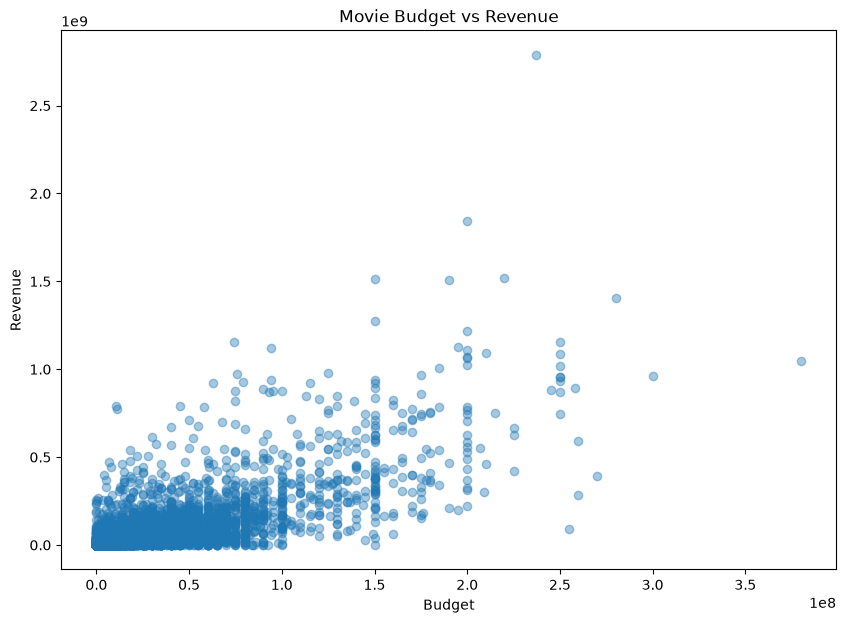

In [65]:
# Budget vs Revenue
plt.figure(figsize=(10, 7))

plt.scatter(
    movie_financial["Budget"],
    movie_financial["Revenue"],
    alpha=0.4
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.show()

In [66]:
#Correlation Analysis
financial_corr = movie_financial[
    [
        "Budget",
        "Revenue",
        "Popularity",
        "Profit",
        "ROI"
    ]
].corr()

financial_corr

,Budget,Revenue,Popularity,Profit,ROI
Budget,1.000000,0.730104,0.503279,0.575073,-0.015817
Revenue,0.730104,1.000000,0.643730,0.978902,-0.009712
Popularity,0.503279,0.643730,1.000000,0.620195,0.000181
Profit,0.575073,0.978902,0.620195,1.000000,-0.006988
ROI,-0.015817,-0.009712,0.000181,-0.006988,1.000000


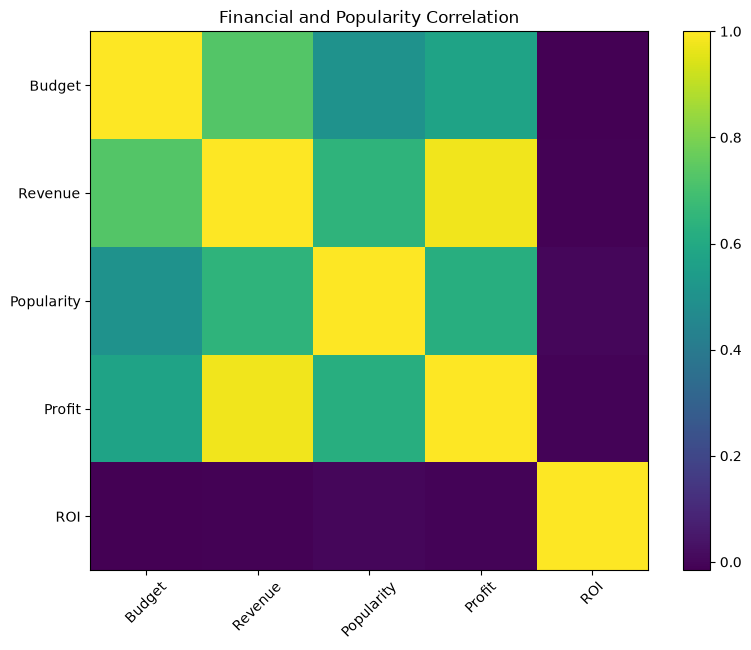

In [67]:
plt.figure(figsize=(9, 7))

plt.imshow(
    financial_corr,
    aspect="auto"
)

plt.xticks(
    range(len(financial_corr.columns)),
    financial_corr.columns,
    rotation=45
)

plt.yticks(
    range(len(financial_corr.columns)),
    financial_corr.columns
)

plt.colorbar()

plt.title(
    "Financial and Popularity Correlation"
)

plt.show()

# Business Insights

The Artist Diary analysis provides insights into artist participation, career activity, genre diversity, international exposure, and movie performance.

## Artist Participation

- Identify the most active artists by number of unique movies.
- Determine whether artist participation is concentrated among a small group.
- Evaluate the distribution of movie participation across artists.

## Career Development

- Identify artists with the longest observed career spans.
- Compare career longevity with movie participation.
- Identify periods of increased artist activity.

## Genre Exposure

- Identify the most common genres across artist appearances.
- Identify artists with the broadest genre diversity.
- Evaluate whether artist participation is concentrated in particular genres.

## International Exposure

- Identify artists associated with multiple production countries.
- Analyze the geographic diversity of movie production.

## Financial Performance

- Identify artists associated with the highest-grossing movies.
- Compare movie budgets and revenues.
- Identify highly profitable movies.
- Examine the relationship between movie popularity and financial performance.

## Important Analytical Consideration

Financial metrics must be calculated at the movie grain before being attributed to artists.

Because one movie can contain multiple artists, directly summing movie revenue from the Artist Diary would double-count revenue.

Therefore:

**Movie-level financial metrics → aggregate at Movie_ID → then associate with artists.**

This principle prevents analytical inflation and ensures that reported metrics are mathematically valid.